<a href="https://colab.research.google.com/github/HarshNA044/machine-learning-practice/blob/main/naive%20bayes/naive_bayes_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Naive Bayes Classifier**
Naive Bayes is a supervised machine learning algorithm used for classification tasks that predicts the category of a data point using probability. It is built on Bayes' Theorem and is called "naive" because it assumes every input feature is completely independent of all other features.

### Mathematical Intuition and Formulas

At the heart of the algorithm is **Bayes' Theorem**, which calculates the probability of an event occurring given prior knowledge of related conditions:

$$P(A|B) = \frac{P(B|A) \cdot P(A)}{P(B)}$$

**Data Sourced from: Kaggle - [PlayTennis Enhanced Weather Dataset](https://www.kaggle.com/datasets/sarveshchhetri/play-tennis-practice-dataset-for-classification?select=playtennis.csv)**

In [ ]:
# importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

* **`train_test_split`**: A helper function that allows us to split dataset into training and testing subsets to prevent overfitting.
* **`LabelEncoder`**: Used to encode categorical text data into numerical integers, as most machine learning algorithms work best with numbers.
* **`CategoricalNB`**: A specific implementation of the Naive Bayes algorithm in scikit-learn tailored for categorical features.
* **`accuracy_score`, `confusion_matrix`, `classification_report`**: Metrics used to evaluate how well our trained machine learning model generalizes to unseen test data.

# Load the Dataset

In [ ]:
url = 'https://raw.githubusercontent.com/HarshNA044/machine-learning-practice/main/naive%20bayes/playtennis.csv'
df = pd.read_csv(url)

# Display the first five rows
df.head()

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Overcast,Mild,Normal,Strong,No
2,Overcast,Cool,Normal,NaN,Yes
3,Rain,Mild,High,Strong,No
4,Rain,Hot,Normal,Weak,Yes


# Understanding the Dataset

In [ ]:
# 1. Check shape of the dataset
print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Check general info and types
df.info()

# 3. Check statistical summary
df.describe(include='all')

Dataset Shape (Rows, Columns): (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Outlook      200 non-null    object
 1   Temperature  200 non-null    object
 2   Humidity     191 non-null    object
 3   Wind         190 non-null    object
 4   PlayTennis   200 non-null    object
dtypes: object(5)
memory usage: 7.9+ KB


,Outlook,Temperature,Humidity,Wind,PlayTennis
count,200,200,191,190,200
unique,3,3,2,2,2
top,Rain,Mild,Normal,Weak,Yes
freq,74,73,99,111,120


# Understanding the Target Variable (PlayTennis)

In [ ]:
# Unique values in target variable
df['PlayTennis'].unique()

array(['No', 'Yes'], dtype=object)

In [ ]:
# Class distribution
df['PlayTennis'].value_counts()

,count
PlayTennis,
Yes,120
No,80


* **`df['PlayTennis'].unique()`**: Displays the unique outcomes in the target column (`Yes` and `No`).
* **`df['PlayTennis'].value_counts()`**: Counts the occurrence of each class. This helps us see if the dataset is balanced (similar number of Yes/No samples) or imbalanced. Understanding this is crucial because severe class imbalance can cause models to bias heavily towards the majority class.

# Data Cleaning & Preprocessing

In [ ]:
# Check for missing values
print("\nMissing Values Per Column:", df.isnull().sum())


Missing Values Per Column: Outlook         0
Temperature     0
Humidity        9
Wind           10
PlayTennis      0
dtype: int64


In [ ]:
# Impute missing values with mode from training set
for col in ['Humidity', 'Wind']:
    col_mode = df[col].mode()[0]
    df[col] = df[col].fillna(col_mode)

# Check if any missing values remain
print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Outlook        0
Temperature    0
Humidity       0
Wind           0
PlayTennis     0
dtype: int64


# Separate Independent and Dependent Variables

In [ ]:
# Separate the features and the target label
X = df.drop(columns=['PlayTennis'])
y = df['PlayTennis']

print("Independent features:\n", X.head())
print("\nTarget feature:\n", y.head())

Independent features:
     Outlook Temperature Humidity    Wind
0     Sunny         Hot     High    Weak
1  Overcast        Mild   Normal  Strong
2  Overcast        Cool   Normal    Weak
3      Rain        Mild     High  Strong
4      Rain         Hot   Normal    Weak

Target feature:
 0     No
1     No
2    Yes
3     No
4    Yes
Name: PlayTennis, dtype: object


# Train-Test Split
Divide dataset into a **Training set** and a **Testing set**

In [ ]:
# Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (160, 4)
Testing set shape: (40, 4)


* **`test_size=0.2`**: Reserves 20% of the dataset (40 rows) for testing, while 80% (160 rows) is used for training.
* **`random_state=42`**: Sets a seed value so that the split is completely reproducible; running this cell multiple times will produce the exact same split.
* **`stratify=y`**: Ensures the target variable's ratio of "Yes" to "No" is identical in both training and test subsets, avoiding bias in splits.

# Encoding, Creating and training the model

Dataset contains entirely categorical features so using the **Categorical Naive Bayes** (`CategoricalNB`) classifier

### How the Categorical Naive Bayes Model Learns:
1. It calculates the **prior probability** of each class ($P(y = \text{Yes})$ and $P(y = \text{No})$) from the training data.
2. For each unique category in each feature (like `Outlook = Overcast`), it calculates the **likelihood probability** of that category appearing given each class label (e.g., $P(\text{Outlook}=\text{Overcast} | y=\text{Yes})$).
3. It uses **Laplace Smoothing** (controlled by parameter `alpha=1.0` by default) to handle cases where a category has zero frequency in the training data, preventing the calculated probabilities from becoming zero.

In [ ]:
# Initialize dictionaries to hold our encoders and empty DataFrames for encoded data
encoders = {}
X_train_encoded = pd.DataFrame()
X_test_encoded = pd.DataFrame()

# Loop through each column to encode the features individually
for col in X_train.columns:
    # Create a LabelEncoder for the column
    le = LabelEncoder()

    # Fit on training data and transform both training and testing sets
    X_train_encoded[col] = le.fit_transform(X_train[col].astype(str))
    X_test_encoded[col] = le.transform(X_test[col].astype(str))

    # Save the encoder for later use
    encoders[col] = le

# Encode the target labels
target_encoder = LabelEncoder()
y_train_encoded = target_encoder.fit_transform(y_train)
y_test_encoded = target_encoder.transform(y_test)

In [ ]:
# Create and train the Categorical Naive Bayes model
nb_model = CategoricalNB(alpha=1.0)
nb_model.fit(X_train_encoded, y_train_encoded)

print("Model trained successfully!")

Model trained successfully!


* **`LabelEncoder()`**: Categorical text cannot be directly computed mathematically. We convert text labels like `Sunny` and `Overcast` into distinct numeric values (0, 1, 2).
* **`fit_transform` vs `transform`**: We use `.fit_transform()` on our data to calculate the mapping and apply it. We only apply `.transform()` on our testing set to ensure our test data is preprocessed using the exact same mapping rules.

* **`CategoricalNB(alpha=1.0)`**: Initializes the model. The parameter `alpha=1.0` enables Laplace smoothing, which avoids zero-probability errors during probability multiplications.
* **`nb_model.fit(X_train, y_train_encoded)`**: The `.fit()` method is the core command that starts the actual training process. The algorithm counts frequencies of combinations of features and labels in `X_train` and `y_train_encoded` to construct its probability tables.

# Make Predictions


In [ ]:
# Predict labels for the testing features using encoded variables
y_pred_encoded = nb_model.predict(X_test_encoded)

# Decode numerical predictions back to original string classes
y_pred = target_encoder.inverse_transform(y_pred_encoded)

# Create a comparison table between actual and predicted outputs
comparison_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

# Display the first ten samples
print("Comparison of Actual vs Predicted Targets:")
display(comparison_df.head(10))

Comparison of Actual vs Predicted Targets:


,Actual,Predicted
0,No,No
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,No,No
5,No,No
6,Yes,Yes
7,Yes,Yes
8,No,Yes
9,No,No


# Evaluate the Model

Model Accuracy on Test Set: 87.5 %


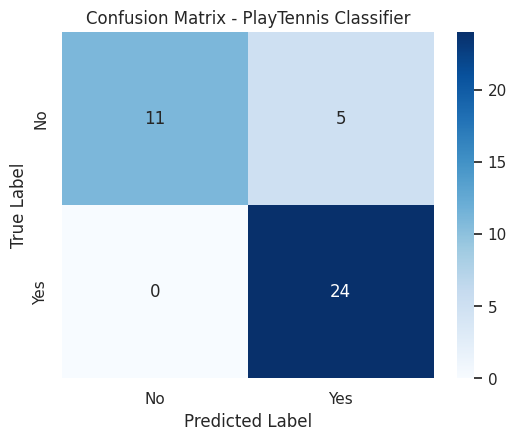


Classification Report:
               precision    recall  f1-score   support

          No       1.00      0.69      0.81        16
         Yes       0.83      1.00      0.91        24

    accuracy                           0.88        40
   macro avg       0.91      0.84      0.86        40
weighted avg       0.90      0.88      0.87        40



In [ ]:
# Calculate accuracy
accuracy = accuracy_score(y_test_encoded, y_pred_encoded)
print("Model Accuracy on Test Set:", accuracy * 100,"%")

# Generate Confusion Matrix
cm = confusion_matrix(y_test_encoded, y_pred_encoded)

# Plot Confusion Matrix
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_encoder.classes_,
            yticklabels=target_encoder.classes_)
plt.title('Confusion Matrix - PlayTennis Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Generate Classification Report
report = classification_report(y_test_encoded, y_pred_encoded, target_names=target_encoder.classes_)
print("\nClassification Report:\n", report)

* **Accuracy**: The ratio of correctly predicted instances to the total instances.
* **Confusion Matrix**: A table showing correct vs incorrect counts for each category:
  * **True Positives (TP)**: Predicted Yes, actually Yes.
  * **True Negatives (TN)**: Predicted No, actually No.
  * **False Positives (FP)**: Predicted Yes, actually No (Type I error).
  * **False Negatives (FN)**: Predicted No, actually Yes (Type II error).
* **Precision**: Measures of all predicted positive items, how many were actually correct: $\frac{TP}{TP + FP}$.
* **Recall**: Measures of all actual positive items, how many did the model correctly catch: $\frac{TP}{TP + FN}$.
* **F1-Score**: The harmonic mean of Precision and Recall, providing a balanced metric: $2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$.

# Predict New Observations

In [ ]:
# Define a new single weather observation
new_sample = pd.DataFrame({
    'Outlook': ['Sunny'],
    'Temperature': ['Mild'],
    'Humidity': ['High'],
    'Wind': ['Weak']
})

print("New Observation:")
new_sample

# Preprocess: Apply same label encoders to the sample
new_sample_encoded = new_sample.copy()
for col in new_sample.columns:
    le = encoders[col]
    new_sample_encoded[col] = le.transform(new_sample[col])

# Predict the outcome
new_pred_encoded = nb_model.predict(new_sample_encoded)
new_pred = target_encoder.inverse_transform(new_pred_encoded)[0]

# Get confidence probabilities
probabilities = nb_model.predict_proba(new_sample_encoded)[0]

print("\nPrediction: Should you Play Tennis? ->", new_pred)
print("Probability of 'No':",probabilities[0]*100,"%")
print("Probability of 'Yes':",probabilities[1]*100,"%")

New Observation:

Prediction: Should you Play Tennis? -> Yes
Probability of 'No': 45.55789169446185 %
Probability of 'Yes': 54.44210830553813 %
